# 91 — Ablation of the Unified Binarization Framework components (two best-ranked algorithms)

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from scipy import stats
from fsbench import experiment as ex, plots
ALGS = json.load(open(ROOT / "results/tables/flagship.json"))["top_group"][:2]
print("ablated algorithms:", ALGS)

ablated algorithms: ['INFO', 'HOA']


In [2]:
variants = {
    "UBF (sign mapping + diverse init + memo + local search)": dict(),
    "stochastic TV-sigmoid instead of sign mapping": dict(transfer="tvs"),
    "stochastic S2 sigmoid instead of sign mapping": dict(transfer="s2"),
    "uniform instead of density-diverse init": dict(init="uniform"),
    "no elite local search": dict(ls_ratio=0.0),
    "no memoisation": dict(cache=False),
}
res = {}
for alg in ALGS:
    for label, kw in variants.items():
        tag = alg if not kw else f"{alg}__" + "_".join(f"{k}-{v}" for k, v in kw.items())
        recs = ex.run_method(alg, tag=tag, subdir=None if not kw else "ablation", **kw)
        recs = [dict(r, method=label, algorithm=alg) for r in recs]
        res[(alg, label)] = recs
df = pd.concat([ex.flatten(r).assign(algorithm=alg) for (alg, _), r in res.items()])

In [3]:
t = df.groupby(["algorithm", "method"])[["f1_macro", "accuracy", "auc_macro", "n_selected", "search_time_s", "n_classifier_fits", "cache_hits"]].mean().round(4)
t.to_csv(ROOT / "results/tables/ablation.csv"); t

f1_macro  \
algorithm method                                                         
HOA       UBF (sign mapping + diverse init + memo + local...    0.8366   
          no elite local search                                 0.8357   
          no memoisation                                        0.8366   
          stochastic S2 sigmoid instead of sign mapping         0.8331   
          stochastic TV-sigmoid instead of sign mapping         0.8312   
          uniform instead of density-diverse init               0.8358   
INFO      UBF (sign mapping + diverse init + memo + local...    0.8365   
          no elite local search                                 0.8334   
          no memoisation                                        0.8365   
          stochastic S2 sigmoid instead of sign mapping         0.8318   
          stochastic TV-sigmoid instead of sign mapping         0.8329   
          uniform instead of density-diverse init               0.8371   

                                                              accuracy  \
algorithm method                                                         
HOA       UBF (sign mapping + diverse init + memo + local...    0.8675   
          no elite local search                                 0.8682   
          no memoisation                                        0.8675   
          stochastic S2 sigmoid instead of sign mapping         0.8639   
          stochastic TV-sigmoid instead of sign mapping         0.8630   
          uniform instead of density-diverse init               0.8655   
INFO      UBF (sign mapping + diverse init + memo + local...    0.8652   
          no elite local search                                 0.8644   
          no memoisation                                        0.8652   
          stochastic S2 sigmoid instead of sign mapping         0.8628   
          stochastic TV-sigmoid instead of sign mapping         0.8629   
          uniform instead of density-diverse init               0.8658   

                                                              auc_macro  \
algorithm method                                                          
HOA       UBF (sign mapping + diverse init + memo + local...     0.9084   
          no elite local search                                  0.9068   
          no memoisation                                         0.9084   
          stochastic S2 sigmoid instead of sign mapping          0.9067   
          stochastic TV-sigmoid instead of sign mapping          0.9044   
          uniform instead of density-diverse init                0.9099   
INFO      UBF (sign mapping + diverse init + memo + local...     0.9097   
          no elite local search                                  0.9052   
          no memoisation                                         0.9097   
          stochastic S2 sigmoid instead of sign mapping          0.9040   
          stochastic TV-sigmoid instead of sign mapping          0.9043   
          uniform instead of density-diverse init                0.9096   

                                                              n_selected  \
algorithm method                                                           
HOA       UBF (sign mapping + diverse init + memo + local...     30.7375   
          no elite local search                                  34.7625   
          no memoisation                                         30.7375   
          stochastic S2 sigmoid instead of sign mapping          26.8625   
          stochastic TV-sigmoid instead of sign mapping          26.3375   
          uniform instead of density-diverse init                29.9125   
INFO      UBF (sign mapping + diverse init + memo + local...     22.0000   
          no elite local search                                  23.0625   
          no memoisation                                         22.0000   
          stochastic S2 sigmoid instead of sign mapping          21.8875   
          stochastic TV-s

In [4]:
full = list(variants)[0]
out = []
for alg in ALGS:
    blk = df[df.algorithm == alg].groupby(["dataset", "classifier", "method"]).f1_macro.mean().unstack()
    for m in blk.columns:
        out.append({"algorithm": alg, "variant": m, "delta_f1_vs_full": (blk[m] - blk[full]).mean(),
                    "p_wilcoxon": stats.wilcoxon(blk[full], blk[m], zero_method="zsplit").pvalue if m != full else np.nan})
pd.DataFrame(out).round(4).to_csv(ROOT / "results/tables/ablation_wilcoxon.csv", index=False); pd.DataFrame(out).round(4)

,algorithm,variant,delta_f1_vs_full,p_wilcoxon
0,INFO,UBF (sign mapping + diverse init + memo + loca...,0.0000,NaN
1,INFO,no elite local search,-0.0030,0.7566
2,INFO,no memoisation,0.0000,1.0000
3,INFO,stochastic S2 sigmoid instead of sign mapping,-0.0046,0.0638
4,INFO,stochastic TV-sigmoid instead of sign mapping,-0.0036,0.1725
5,INFO,uniform instead of density-diverse init,0.0006,0.6955
6,HOA,UBF (sign mapping + diverse init + memo + loca...,0.0000,NaN
7,HOA,no elite local search,-0.0009,0.8429
8,HOA,no memoisation,0.0000,1.0000
9,HOA,stochastic S2 sigmoid instead of sign mapping,-0.0035,0.1677


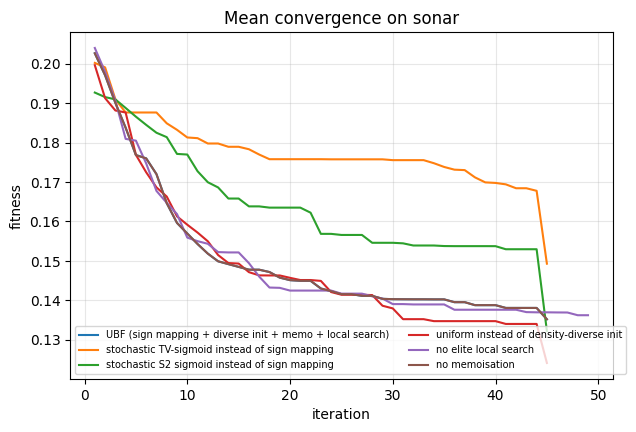

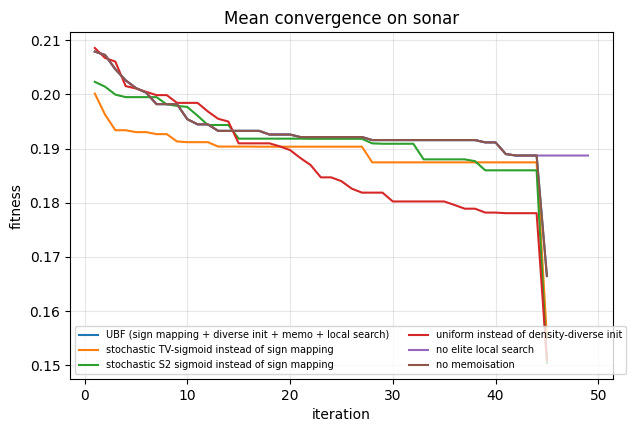

In [5]:
for alg in ALGS:
    plots.convergence_compare({lab: r for (a, lab), r in res.items() if a == alg}, "sonar", name=f"ablation_convergence_{alg}_sonar")
